# Heuers' statistical Football model

The following implementation aims to recreate the Football model of Prof. Dr. Andreas Heuer.

In [73]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from functools import lru_cache
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
AVG_HF_ADV = 0.3672508214676889  # from DB
AVG_GA = 2.7175246440306681 # from DB
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [74]:
# Helperfunctions
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)
    
    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


## Step 1 - Homefield advantage

In [75]:
df_country_season_homefield_adv = pd.read_csv("data/hf_adv.csv", sep=";")

df_country_season_homefield_adv

,country,season,matchnumber,ht_name,at_name,curr_hf_adv,past_hf_adv,actual_hf_adv
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.0,1
1,ENG,14,1,Burnley,Chelsea,0.000000,0.0,-2
2,ENG,14,1,Leicester,Everton,0.000000,0.0,0
3,ENG,14,1,Liverpool,Southampton,0.000000,0.0,1
4,ENG,14,1,Man Utd,Swansea,0.000000,0.0,-1
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,0.275676,0.0,0
9126,ITA,18,38,Frosinone,Chievo,0.275676,0.0,0
9127,ITA,18,38,Inter,Empoli,0.275676,0.0,1
9128,ITA,18,38,Sampdoria,Juventus,0.275676,0.0,2


In [76]:
def h_country_season_homefield_adv(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_HF_ADV
        
    sub_df = df_country_season_homefield_adv.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_hf_adv",
                "curr_hf_adv"]].values
    y = sub_df["actual_hf_adv"].values

    model = LinearRegression(positive=True).fit(X, y)
    
    input_df = df_country_season_homefield_adv.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_hf_adv",
                      "curr_hf_adv"]].values

    return model.predict(input)[0]


print("Homefield advantage:", h_country_season_homefield_adv("ENG", 17, 8))


Homefield advantage: 0.3469387755102041


## Step 2 - Goalamount per match

In [77]:
df_country_season_goalamount = pd.read_csv(
    "data/ga.csv", sep=";")

df_country_season_goalamount

,country,season,matchnumber,ht_name,at_name,curr_ga,past_ga,actual_ga
0,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,3
1,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,4
2,ENG,14,1,Leicester,Everton,0.000000,0.000000,4
3,ENG,14,1,Liverpool,Southampton,0.000000,0.000000,3
4,ENG,14,1,Man Utd,Swansea,0.000000,0.000000,3
...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Fiorentina,CFC Genoa,2.675676,2.735965,0
9126,ITA,18,38,Frosinone,Chievo,2.675676,2.735965,0
9127,ITA,18,38,Inter,Empoli,2.675676,2.735965,3
9128,ITA,18,38,Sampdoria,Juventus,2.675676,2.735965,2


In [78]:
def h_country_season_goalamount(country, season, matchnumber):
    if matchnumber == 1:
        return AVG_GA
        
    sub_df = df_country_season_goalamount.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_ga",
                "curr_ga"]].values 
    y = sub_df["actual_ga"].values

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_country_season_goalamount.query(
        f"country == '{country}' and season == {season} and matchnumber == {matchnumber}")
    input = input_df[["past_ga",
                      "curr_ga"]].values

    return model.predict(input)[0]


print("Goalamount:", h_country_season_goalamount("GER", 18, 8))


Goalamount: 2.758234611337038


## Step 3: Teamstrength and expected goaldifference + Step 4: Specialty for promoters

In [79]:
df_matches = pd.read_csv('data/matches_heuer.csv', sep=';')

ga_label = "actual_goalamount"
gd_label = "actual_goaldiff"

df_matches

,country,season,matchnumber,teamname,curr_eff_chancediff,past_chancediff_combined,curr_eff_chanceamount,past_chanceamount,curr_fitness,market_value_ln_relative,is_promoter,is_home,actual_goalamount,actual_goaldiff
0,ENG,14,1,Queens Park Rangers,0.000000,0.000000,0.000000,0.000000,0.000000,-0.392415,True,True,1,-1
1,ENG,14,1,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,-0.348740,False,False,1,1
2,ENG,14,1,Newcastle,0.000000,0.000000,0.000000,0.000000,0.000000,-0.169272,False,True,2,-2
3,ENG,14,1,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,1.002768,False,False,2,2
4,ENG,14,1,Burnley,0.000000,0.000000,0.000000,0.000000,0.000000,-1.140622,True,True,4,-2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18255,ITA,18,38,Napoli,5.242267,5.293421,3.415385,8.877193,3.375719,1.070083,False,False,5,-1
18256,ITA,18,38,Inter,2.881676,2.380263,1.042860,6.754386,1.768259,1.024225,False,True,3,1
18257,ITA,18,38,Empoli,-3.462648,-3.058772,-0.805584,4.403509,2.088522,-0.738824,True,False,3,-1
18258,ITA,18,38,Cagliari,-3.170633,-1.972368,-1.823289,4.824561,-3.719535,-0.358838,False,True,3,-1


In [80]:
def h_teamstrength(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chancediff_combined",
                "curr_eff_chancediff", "curr_fitness", "market_value_ln_relative"]].values
    y = []

    # one team is only responsible for half of the goaldiff
    for index, row in sub_df.iterrows():
        goal_diff = row["actual_goaldiff"]
        if row["is_home"]:
            goal_diff -= AVG_HF_ADV
        else:
            goal_diff += AVG_HF_ADV
        y.append(goal_diff/2)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")

    # Homefield advantage correction
    homefield_matches = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber} and teamname == '{teamname}' and is_home").count()["is_home"]

    if matchnumber > 1:
        additional_homefield_matches = homefield_matches - \
            ((matchnumber - 1) - homefield_matches)
        if additional_homefield_matches > 0:
            input_df["curr_eff_chancediff"] -= (additional_homefield_matches * \
                h_country_season_homefield_adv(country, season, matchnumber) * 4) / (matchnumber - 1)

    # Step 4: Specialty for promoters
    if input_df.iloc[0]["is_promoter"]:
        input_df["past_chancediff_combined"] = input_df["past_chancediff_combined"] * \
            0.45 * model.coef_[1]
        input_df["curr_eff_chancediff"] = input_df["curr_eff_chancediff"] * 0.45 * model.coef_[1]

    input = input_df[["past_chancediff_combined",
                      "curr_eff_chancediff", "curr_fitness","market_value_ln_relative"]].values

    teamstrength = model.predict(input)[0]

    if input_df.iloc[0]["is_promoter"]:
        teamstrength -= (13/34)

    return teamstrength


for season in [14,15,16,17,18]:
    print(season, "Teamstrength Borussia Dortmund:", h_teamstrength(
        "GER", season, 34, "Borussia Dortmund"))


14 Teamstrength Borussia Dortmund: 0.4567070275380535
15 Teamstrength Borussia Dortmund: 0.47979663310275955
16 Teamstrength Borussia Dortmund: 0.5279726337636228
17 Teamstrength Borussia Dortmund: 0.498815965215907
18 Teamstrength Borussia Dortmund: 0.4022866510279267


## Step 5: Expected goalamount per match

In [81]:
def h_goalamount_from_avg_per_match(country, season, matchnumber, teamname):
    if matchnumber == 1:
        return 0

    sub_df = df_matches.query(
        f"season == {season} and matchnumber < {matchnumber}")

    X = sub_df[["past_chanceamount", "curr_eff_chanceamount"]].values 
    y = []
    for index, row in sub_df.iterrows():
        y.append(row["actual_goalamount"] - AVG_GA)

    model = LinearRegression(positive=True).fit(X, y)

    input_df = df_matches.query(
        f"season == {season} and matchnumber == {matchnumber} and teamname == '{teamname}'")
    input = input_df[["past_chanceamount", "curr_eff_chanceamount"]].values

    return model.predict(input)[0]

print("Goalamount from avg:", h_goalamount_from_avg_per_match("GER", 16, 19, "Bayern"))


Goalamount from avg: 0.5728719051280874


## Step 6: Predicted Goals

In [82]:
def predicted_goals(country, season, matchnumber, hometeam, awayteam):
    goalamount = h_goalamount_from_avg_per_match(
        country, season, matchnumber, hometeam) + h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam) + h_country_season_goalamount(country, season, matchnumber)
    goaldiff = h_country_season_homefield_adv(country, season, matchnumber) + h_teamstrength(country, season, matchnumber, hometeam) - h_teamstrength(country, season, matchnumber, awayteam)
    return (goalamount, goaldiff)


## Step 7: Dependence on matchnumber

In [83]:
def matchnumber_goalamount_multiplier(country, matchnumber):
    # Uncertain
    if country == 'GER':
        if matchnumber < 18:
            return 1.02
        elif matchnumber < 31:
            return 0.945
        else:
            return 1.2
    else:
        if matchnumber < 19:
            return 1.02
        elif matchnumber < 35:
            return 0.945
        else:
            return 1.2


## Final: Full run on dataset to measure goalamount and goaldifference error

In [84]:
def predict(country, season, matchnumber, hometeam, awayteam):
    amount, diff = predicted_goals(country, season, matchnumber, hometeam, awayteam)

    home_score, away_score = score_from_amount_and_diff(amount, diff)

    home_score *= matchnumber_goalamount_multiplier(country, matchnumber)
    away_score *= matchnumber_goalamount_multiplier(country, matchnumber)

    return (home_score+ away_score), (home_score - away_score)


## Error per season

In [85]:
do_entire_run = False

if do_entire_run:
    error_dict = dict()
    ga_generalization_error, gd_generalization_error = 0,0
    ga_error, gd_error = [], []
    ga_preds, gd_preds = [], []

    for index, row in df_matches.iterrows():
        if index % 2 == 0:
            hometeam = row["teamname"]
            continue
        else:
            print("Predicting:", row["country"],
                  row["season"], row["matchnumber"], hometeam, row["teamname"])
            awayteam = row["teamname"]
            ga_pred, gd_pred = predict(
                row["country"], row["season"], row["matchnumber"], hometeam, awayteam)

            curr_ga_error = np.abs(ga_pred - row["actual_goalamount"])
            curr_gd_error = np.abs(gd_pred + row["actual_goaldiff"])

            # error list for distribution
            if row["season"] == 18:
                ga_error.append(round(ga_pred - row[ga_label]))
                gd_error.append(round(gd_pred + row[gd_label]))

            # preds for plotting
            if row["season"] == 18:
                ga_preds.append(ga_pred)
                gd_preds.append(gd_pred)

            # generalization error
            if row["season"] in [17,18]:
                ga_generalization_error += curr_ga_error
                gd_generalization_error += curr_gd_error 

            # for training error plot
            if not row["season"] in error_dict.keys():
                error_dict[row["season"]] = {}
            if not row["country"] in error_dict[row["season"]].keys():
                error_dict[row["season"]][row["country"]] = {"ga":0,"gd":0}

            if row["country"] == "GER":
                error_dict[row["season"]][row["country"]
                                        ]["ga"] += (curr_ga_error / 306)
                error_dict[row["season"]][row["country"]
                                        ]["gd"] += (curr_gd_error / 306)
            else:
                error_dict[row["season"]][row["country"]
                                          ]["ga"] += (curr_ga_error / 380)
                error_dict[row["season"]][row["country"]
                                          ]["gd"] += (curr_gd_error / 380)

    print()
    print("GA generalization error:", ga_generalization_error / (NUM_OF_MATCHES_IN_A_SEASON * 2))
    print("GD generalization error:", gd_generalization_error /
            (NUM_OF_MATCHES_IN_A_SEASON * 2))


# GA generalization error: 1.325188388777366
# GD generalization error: 1.2775430982490708


In [86]:
if do_entire_run:
        print("country;season;ga_error;gd_error")
        for a in error_dict.keys():
                for b in error_dict[a].keys():
                                print(str(b)+";"+str(a)+";" +
                                        str(error_dict[a][b]["ga"])+";"+str(error_dict[a][b]["gd"]))


In [87]:
if do_entire_run:
        distribution_data = dict()
        for x in range(-10, 10):
                distribution_data[x] = {}
                for y in range(-10, 10):
                        distribution_data[x][y] = 0

        for ga, gd in zip(ga_error, gd_error):
                distribution_data[round(ga)][round(gd)] += 1

        print("ga prediction - actual ga;gd prediction - actual gd;count")
        for key in range(-10, 10):
                for x in distribution_data[key].keys():
                        if key < 4 and key > -4 and x < 4 and x > -4:
                                print(str(key)+";"+str(x)+";" +
                                        str(distribution_data[key][x]))


In [88]:
if do_entire_run:
        print("ga_pred;gd_pred")
        for ga, gd in zip(ga_preds, gd_preds):
                print(str(ga)+";"+str(gd))


## Plotting

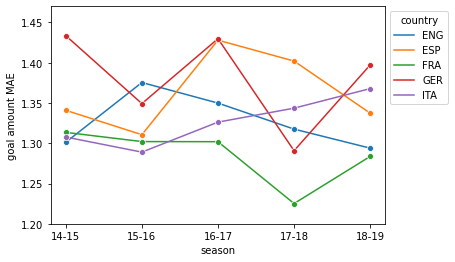

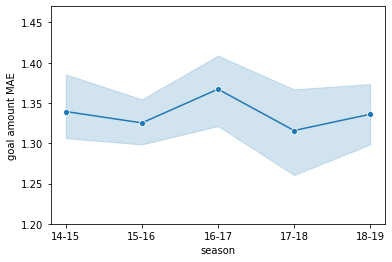

In [89]:
abs_error_df = pd.read_csv("data/abs_error.csv",sep=";")

g = sns.lineplot(x="season", y="ga_error",
           hue="country", data=abs_error_df, marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14,15,16,17,18],["14-15","15-16","16-17","17-18","18-19"])
plt.ylabel("goal amount MAE")
plt.ylim(1.20,1.47)
plt.show()

sns.lineplot(x="season", y="ga_error",
            data=abs_error_df, marker="o")
plt.ylabel("goal amount MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylim(1.20, 1.47)
plt.show()


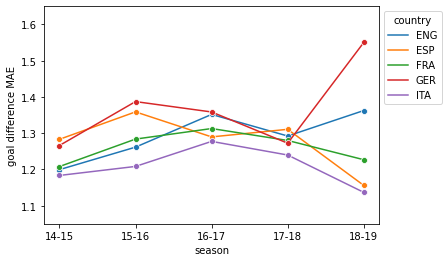

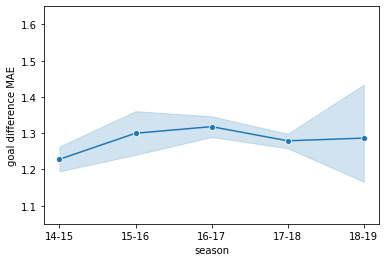

In [90]:
g = sns.lineplot(x="season", y="gd_error",
             hue="country", data=abs_error_df,  marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylabel("goal difference MAE")
plt.ylim(1.05, 1.65)
plt.show()

sns.lineplot(x="season", y="gd_error",
             data=abs_error_df,  marker="o")
plt.ylabel("goal difference MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylim(1.05, 1.65)
plt.show()


## prediction distribution

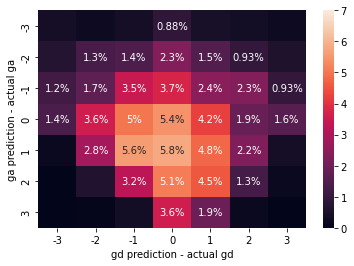

In [91]:
heatmap_df = pd.read_csv("data/distribution.csv",sep=";")

heatmap_df["count"] = heatmap_df["count"].apply(lambda x: (x / NUM_OF_MATCHES_IN_A_SEASON) * 100)

heatmap_df = heatmap_df.pivot(
"ga prediction - actual ga", "gd prediction - actual gd", "count")

ax = sns.heatmap(heatmap_df, annot=True, vmax=7)
for t in ax.texts:
    if float(t.get_text()) > 0.75:
        t.set_text(t.get_text() + "%")
    else:
        t.set_text("")
plt.show()


## Standings of team strengths

In [92]:
do_create_team_strength_table = False

if do_create_team_strength_table:
    team_strengths = []
    subjected_teams = df_matches.query("season == 18")["teamname"].unique()
    for team in subjected_teams:
        subject_match = df_matches.query(f"season == 18 and teamname == '{team}'").iloc[0]
        if subject_match["country"] == "GER":
            team_strengths.append((h_teamstrength(
                subject_match["country"], 18, 34, team), subject_match["country"], team))
        else:
            team_strengths.append((h_teamstrength(
                subject_match["country"], 18, 38, team), subject_match["country"], team))

    team_strengths.sort(reverse=True)
    i = 1
    for team in team_strengths:
        print(str(i) + ".", team[1],
              team[2], round(team[0], 2))
        i += 1


## Prediction of a match

In [93]:

country, season, matchnumber, hometeam, awayteam = "ENG", 18, 20, "Southampton", "Man City"

home_adv = h_country_season_homefield_adv(country,season,matchnumber)
avg_ga = h_country_season_goalamount(country, season, matchnumber)
ht_strength = h_teamstrength(country,season,matchnumber,hometeam)
at_strength = h_teamstrength(country, season, matchnumber, awayteam)
ht_ga = h_goalamount_from_avg_per_match(country, season, matchnumber, hometeam)
at_ga = h_goalamount_from_avg_per_match(country, season, matchnumber, awayteam)
pred_ga = avg_ga+ ht_ga + at_ga
pred_gd = home_adv + ht_strength - at_strength
ht_score, at_score = score_from_amount_and_diff(pred_ga, pred_gd)
ht_score_final = round(ht_score * matchnumber_goalamount_multiplier(country, matchnumber),2)
at_score_final = round(at_score * \
    matchnumber_goalamount_multiplier(country, matchnumber),2)

print(f"{country} - season: {season} - match week: {matchnumber} | {hometeam} vs. {awayteam}")
print("Step 1 - Home advantage:", round(home_adv,2))
print("Step 2 - Average goal amount:", round(avg_ga,2))
print("Step 3 - Team strength: home team:", round(ht_strength,2),
      "| away team:", round(at_strength, 2))
print(
     f"     -> predicted goal difference = home advantage + home team strength - away team strength")
print(
    f"                                  = {round(home_adv,2)} + ({round(ht_strength,2)}) - {round(at_strength,2)} = {round(pred_gd, 2)}")
print("Step 4 - Specialty for promoters: Does not apply")
print("Step 5 - Goal amount influence: home team:",
      round(ht_ga, 2), "| away team:", round(at_ga, 2))
print(
    f"     -> predicted goal amount = average goal amount + home team goal amount influence + away team goal amount influence")
print(f"                              = {round(avg_ga,2)} + ({round(ht_ga,2)}) + {round(at_ga,2)} =", round(pred_ga, 2))
print("Step 6 - Predicted goals:", round(ht_score, 2), ":", round(at_score,2))
print("Step 7 - Dependence on match week: Scores * 0.945")
print(f"     -> {round(ht_score, 2)} * 0.945 = {ht_score_final} , {round(at_score, 2)} * 0.945 = {at_score_final}")
print("")
print("Final predicted goal amount:", ht_score_final+at_score_final)
print("Final predicted goal difference:", ht_score_final-at_score_final)
print("Final predicted result:", ht_score_final,":", at_score_final)
print("Actual goal amount: 4")
print("Actual goal difference: -2")
print("Actual result: 1:3")
print()

print("Absolute error goal amount: |2.92 - 4| = 1.08")
print("Absolute error goal difference: |(-0.28) - (-2)| = 1.72")


ENG - season: 18 - match week: 20 | Southampton vs. Man City
Step 1 - Home advantage: 0.27
Step 2 - Average goal amount: 2.72
Step 3 - Team strength: home team: -0.05 | away team: 0.51
     -> predicted goal difference = home advantage + home team strength - away team strength
                                  = 0.27 + (-0.05) - 0.51 = -0.29
Step 4 - Specialty for promoters: Does not apply
Step 5 - Goal amount influence: home team: -0.01 | away team: 0.37
     -> predicted goal amount = average goal amount + home team goal amount influence + away team goal amount influence
                              = 2.72 + (-0.01) + 0.37 = 3.09
Step 6 - Predicted goals: 1.4 : 1.69
Step 7 - Dependence on match week: Scores * 0.945
     -> 1.4 * 0.945 = 1.32 , 1.69 * 0.945 = 1.6

Final predicted goal amount: 2.92
Final predicted goal difference: -0.28
Final predicted result: 1.32 : 1.6
Actual goal amount: 4
Actual goal difference: -2
Actual result: 1:3

Absolute error goal amount: |2.92 - 4| = 1.08


## Prediction plotting

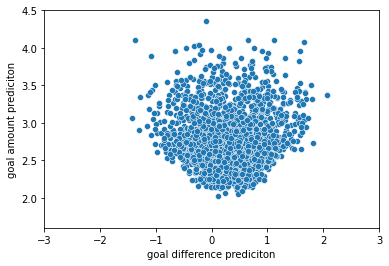

In [97]:
preds_df = pd.read_csv("data/predictions.csv",sep=";")

sns.scatterplot(preds_df["gd_pred"], preds_df["ga_pred"])
plt.ylabel("goal amount prediciton")
plt.xlabel("goal difference prediciton")
plt.ylim(1.6, 4.5)
plt.xlim(-3, 3)

plt.show()
